# Visualize interferograms

In [2]:
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt

## Check one (stiched) interferogram

In [40]:
# Path to the first interferogram
int_file = Path(
    "/home/lukas/projects/ADUCAT/data/sweets_fork_testenv/dolphin/interferograms/20250109_20250121.int.tif"
)

In [41]:
with rasterio.open(int_file) as src:
    print(f"Resolution: {src.res}")
    print(f"CRS:        {src.crs}")
    print(f"Dimensions: {src.width} x {src.height} pixels")
    print(f"Bounds:     {src.bounds}")
    print(f"Data type:  {src.dtypes[0]}")
    print(f"Band count: {src.count}")

Resolution: (30.0, 30.0)
CRS:        EPSG:32633
Dimensions: 1022 x 786 pixels
Bounds:     BoundingBox(left=587520.0, bottom=5330010.0, right=618180.0, top=5353590.0)
Data type:  complex64
Band count: 1


In [42]:
def plot_interferogram(int_file):
    # Read complex interferogram
    with rasterio.open(int_file) as src:
        interferogram = src.read(1, masked=True)

    print(f"File: {int_file.name}")
    print(f"Shape: {interferogram.shape}")
    print(f"Data type: {interferogram.dtype}")
    print(f"CRS: {src.crs}")

    # Convert to complex array, preserving invalid pixels as NaN
    data = interferogram.filled(np.nan + 1j * np.nan)

    # Derive phase (radians) and amplitude
    phase = np.angle(data)
    amplitude = np.abs(data)

    # Plot 1: Wrapped phase
    fig, ax = plt.subplots(figsize=(12, 7))

    im = ax.imshow(
        phase,
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )

    ax.set_title("Wrapped Interferometric Phase")
    ax.set_xlabel("Range pixel")
    ax.set_ylabel("Azimuth pixel")

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.set_label("Phase (radians)")
    cbar.set_ticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    cbar.set_ticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])

    plt.tight_layout()
    plt.show()

    # Plot 2: Amplitude
    fig, ax = plt.subplots(figsize=(12, 7))

    im = ax.imshow(
        amplitude,
        cmap="gray",
        interpolation="nearest",
    )

    ax.set_title("Interferogram Amplitude")
    ax.set_xlabel("Range pixel")
    ax.set_ylabel("Azimuth pixel")

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.set_label("Amplitude")

    plt.tight_layout()
    plt.show()

File: 20250109_20250121.int.tif
Shape: (786, 1022)
Data type: complex64
CRS: EPSG:32633


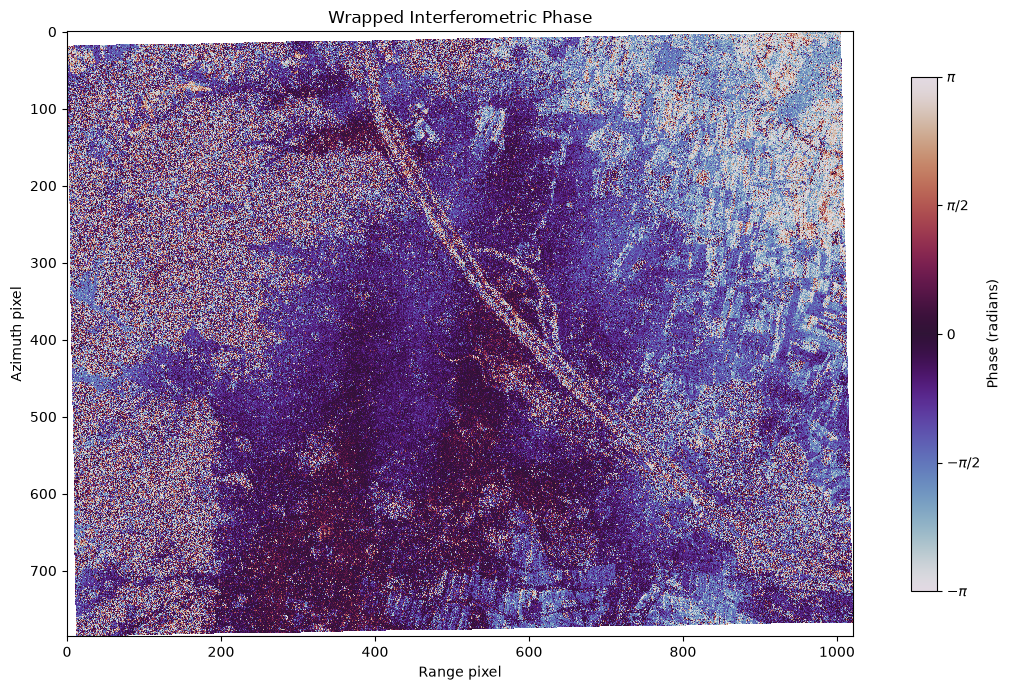

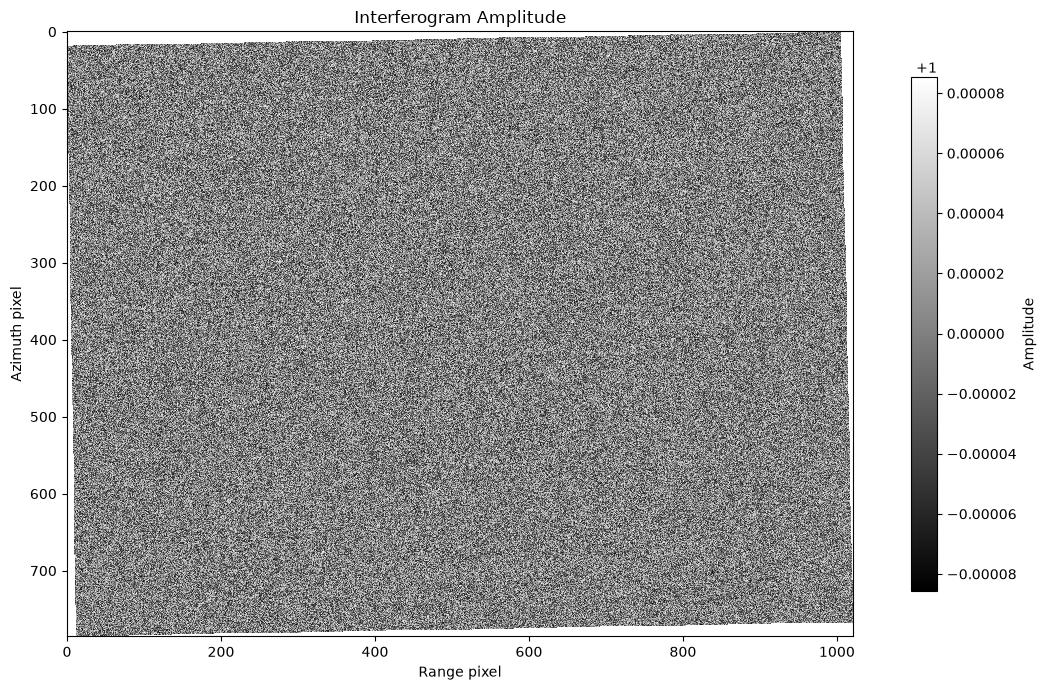

In [43]:
plot_interferogram(int_file)

In [10]:

with rasterio.open(int_file) as src:
    z = src.read(1)
    print("Shape:", z.shape)
    print("Dtype:", z.dtype)
    print("NoData:", src.nodata)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)

# Basic validity checks
finite = np.isfinite(z.real) & np.isfinite(z.imag)
zero = finite & (np.abs(z) == 0)
amplitude = np.abs(z)

print(f"Finite pixels: {finite.mean():.2%}")
print(f"Exact-zero pixels: {zero.mean():.2%}")
print(f"Non-finite pixels: {(~finite).mean():.2%}")

valid_amp = amplitude[finite & (amplitude > 0)]
if valid_amp.size:
    print("Amplitude percentiles:")
    print(np.percentile(valid_amp, [1, 5, 25, 50, 95, 99]))

Shape: (1178, 1531)
Dtype: complex64
NoData: 0.0
CRS: EPSG:32633
Bounds: BoundingBox(left=587540.0, bottom=5330020.0, right=618160.0, top=5353580.0)
Transform: | 20.00, 0.00, 587540.00|
| 0.00,-20.00, 5353580.00|
| 0.00, 0.00, 1.00|
Finite pixels: 100.00%
Exact-zero pixels: 44.56%
Non-finite pixels: 0.00%
Amplitude percentiles:
[0.99993503 0.99994552 0.99997276 1.00000036 1.00005436 1.00006581]


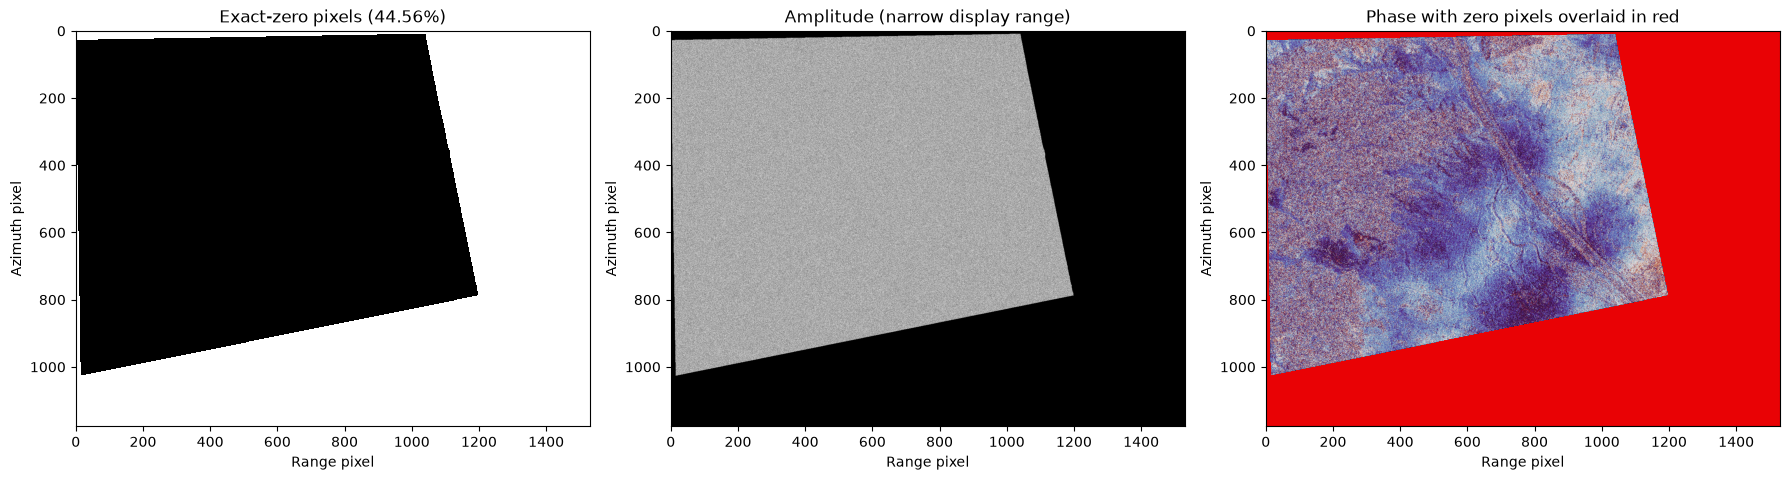

In [11]:
with rasterio.open(int_file) as src:
    z = src.read(1)

amplitude = np.abs(z)
phase = np.angle(z)
zero = (z.real == 0) & (z.imag == 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(zero, cmap="gray", vmin=0, vmax=1,
               interpolation="nearest")
axes[0].set_title(f"Exact-zero pixels ({zero.mean():.2%})")

axes[1].imshow(amplitude, cmap="gray", vmin=0.9998, vmax=1.0001)
axes[1].set_title("Amplitude (narrow display range)")

axes[2].imshow(phase, cmap="twilight", vmin=-np.pi, vmax=np.pi)
axes[2].imshow(
    np.ma.masked_where(~zero, zero),
    cmap="autumn",
    alpha=0.9,
    interpolation="nearest",
)
axes[2].set_title("Phase with zero pixels overlaid in red")

for ax in axes:
    ax.set_xlabel("Range pixel")
    ax.set_ylabel("Azimuth pixel")

plt.tight_layout()
plt.show()

Matching pixels: 361


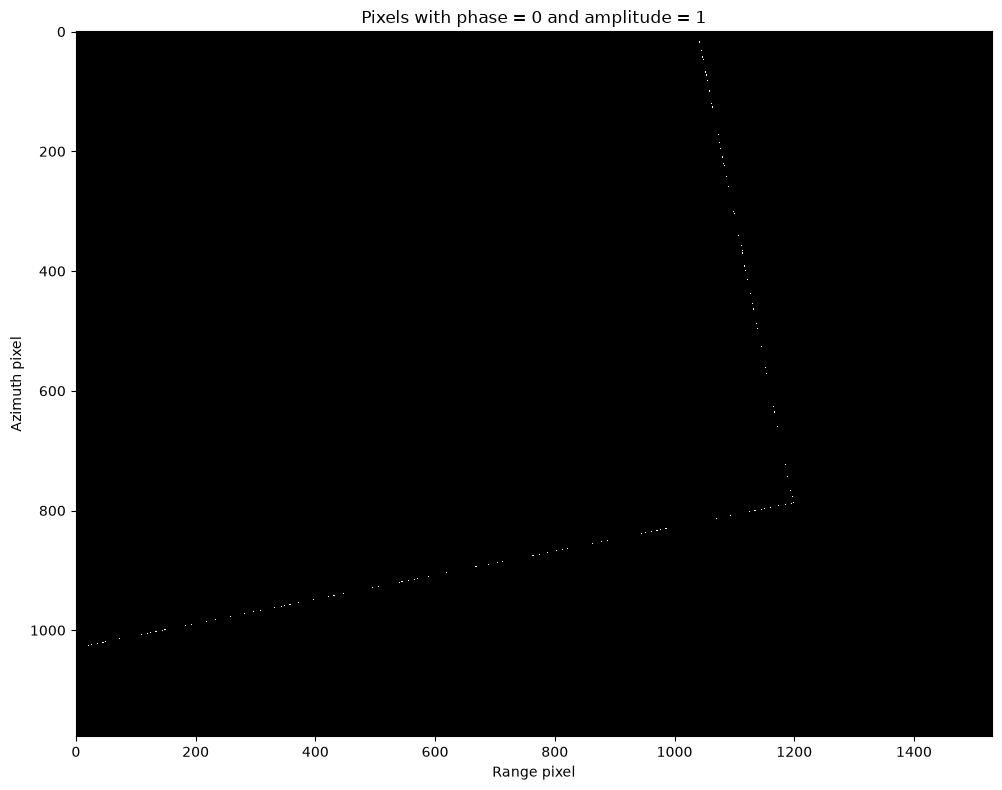

In [12]:
# z = your complex interferogram array

phase = np.angle(z)
amplitude = np.abs(z)

# Select pixels with phase = 0 and amplitude = 1
tol = 0
matches = (
    np.isfinite(z.real)
    & np.isfinite(z.imag)
    & np.isclose(phase, 0, atol=tol)
    & np.isclose(amplitude, 1, atol=tol)
)

print(f"Matching pixels: {np.count_nonzero(matches):,}")

# Plot only matching pixels
plt.figure(figsize=(14, 8))
plt.imshow(matches, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.title("Pixels with phase = 0 and amplitude = 1")
plt.xlabel("Range pixel")
plt.ylabel("Azimuth pixel")
plt.tight_layout()
plt.show()

## Interferograms from single bursts

In [13]:
burst = "t073_154935_iw1"


# Path to the first interferogram
int_file = Path(
    f"/home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/{burst}/interferograms/20220101_20220113.int.vrt"
)

print(f"File: {int_file}")

File: /home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/t073_154935_iw1/interferograms/20220101_20220113.int.vrt


File: 20220101_20220113.int.vrt
Shape: (1642, 3319)
Data type: complex64
CRS: EPSG:32633


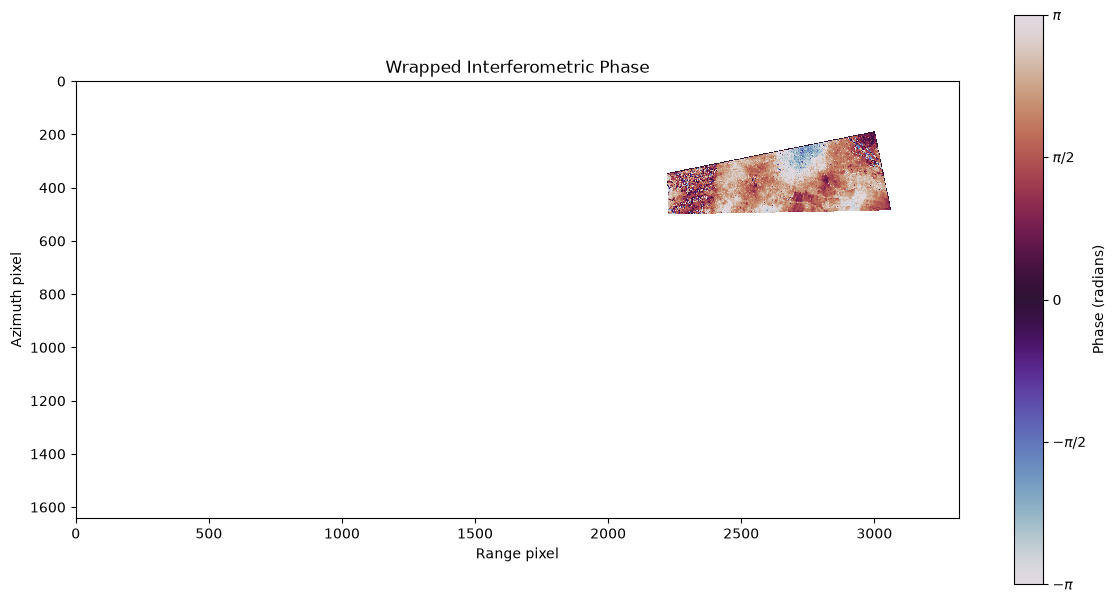

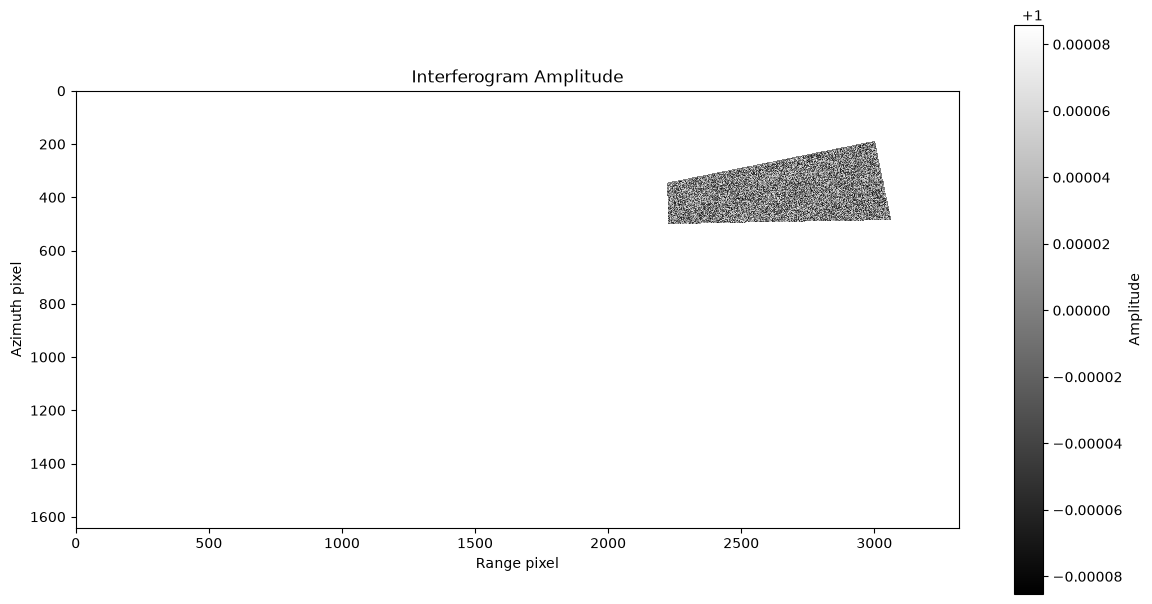

In [14]:
plot_interferogram(int_file)

In [15]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

def plot_interferogram_geographic(int_file):
    # Read complex interferogram and its georeferencing
    with rasterio.open(int_file) as src:
        interferogram = src.read(1)
        valid = src.read_masks(1) > 0

        crs = src.crs
        transform = src.transform
        bounds = src.bounds
        width, height = src.width, src.height

    print(f"File: {int_file}")
    print(f"Shape: {interferogram.shape}")
    print(f"Data type: {interferogram.dtype}")
    print(f"CRS: {crs}")
    print(f"Bounds: {bounds}")

    # A geographic reprojection requires a known source CRS
    if crs is None:
        raise ValueError(
            "This raster has no CRS. Geographic coordinates "
            "cannot be calculated from this file alone."
        )

    valid &= (
        np.isfinite(interferogram.real)
        & np.isfinite(interferogram.imag)
    )

    # Calculate output grid in longitude/latitude
    dst_crs = "EPSG:32633"

    dst_transform, dst_width, dst_height = (
        calculate_default_transform(
            crs,
            dst_crs,
            width,
            height,
            *bounds,
        )
    )

    # Reproject real and imaginary parts separately
    real_src = np.where(
        valid, interferogram.real, np.nan
    ).astype(np.float32)

    imag_src = np.where(
        valid, interferogram.imag, np.nan
    ).astype(np.float32)

    real_dst = np.full(
        (dst_height, dst_width), np.nan, dtype=np.float32
    )
    imag_dst = np.full_like(real_dst, np.nan)

    for src_array, dst_array in [
        (real_src, real_dst),
        (imag_src, imag_dst),
    ]:
        reproject(
            source=src_array,
            destination=dst_array,
            src_transform=transform,
            src_crs=crs,
            src_nodata=np.nan,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
            init_dest_nodata=True,
        )

    # Reconstruct the complex interferogram after reprojection
    data = real_dst + 1j * imag_dst
    valid_dst = (
        np.isfinite(real_dst) & np.isfinite(imag_dst)
    )

    phase = np.ma.array(
        np.angle(data), mask=~valid_dst
    )
    amplitude = np.ma.array(
        np.abs(data), mask=~valid_dst
    )

    # Geographic extent of the reprojected raster
    left = dst_transform.c
    top = dst_transform.f
    right = left + dst_width * dst_transform.a
    bottom = top + dst_height * dst_transform.e
    extent = (left, right, bottom, top)

    # Plot 1: Wrapped phase
    fig, ax = plt.subplots(figsize=(12, 7))

    im = ax.imshow(
        phase,
        extent=extent,
        origin="upper",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )

    ax.set_title("Wrapped Interferometric Phase")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_aspect("auto")

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.set_label("Phase (radians)")
    cbar.set_ticks([
        -np.pi, -np.pi / 2, 0, np.pi / 2, np.pi
    ])
    cbar.set_ticklabels([
        r"$-\pi$", r"$-\pi/2$", "0",
        r"$\pi/2$", r"$\pi$"
    ])

    plt.tight_layout()
    plt.show()

    # Plot 2: Amplitude
    fig, ax = plt.subplots(figsize=(12, 7))

    im = ax.imshow(
        amplitude,
        extent=extent,
        origin="upper",
        cmap="gray",
        interpolation="nearest",
    )

    ax.set_title("Interferogram Amplitude")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_aspect("auto")

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.set_label("Amplitude")

    plt.tight_layout()
    plt.show()

File: /home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/t073_154935_iw1/interferograms/20220101_20220113.int.vrt
Shape: (1642, 3319)
Data type: complex64
CRS: EPSG:32633
Bounds: BoundingBox(left=521130.0, bottom=5295780.0, right=620700.0, top=5345040.0)


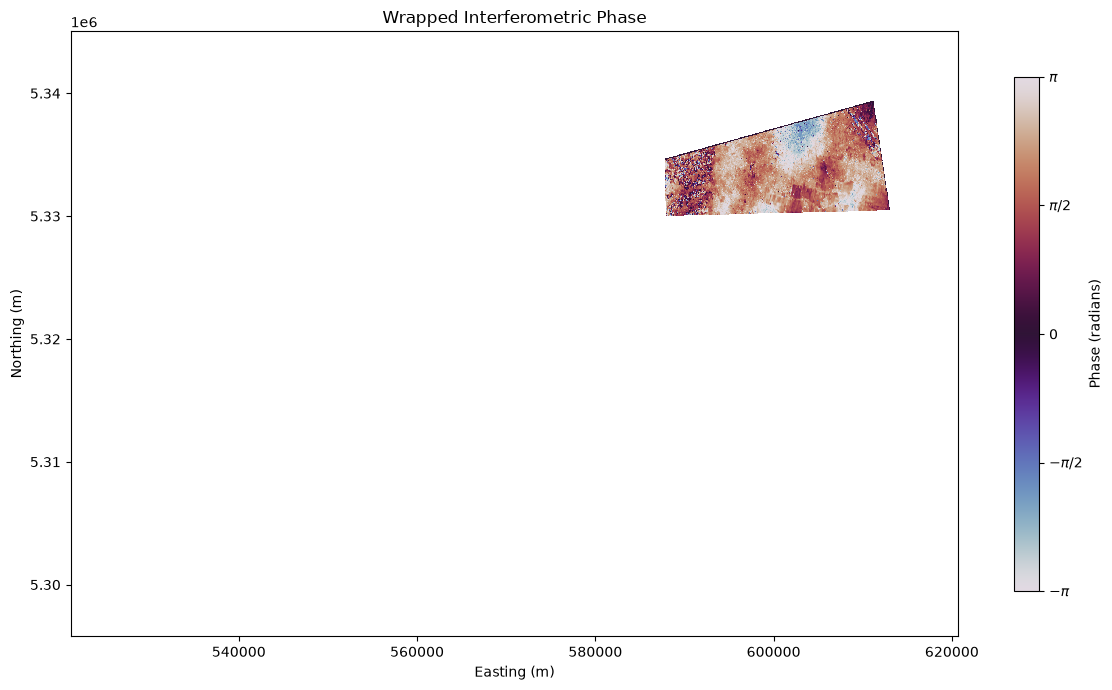

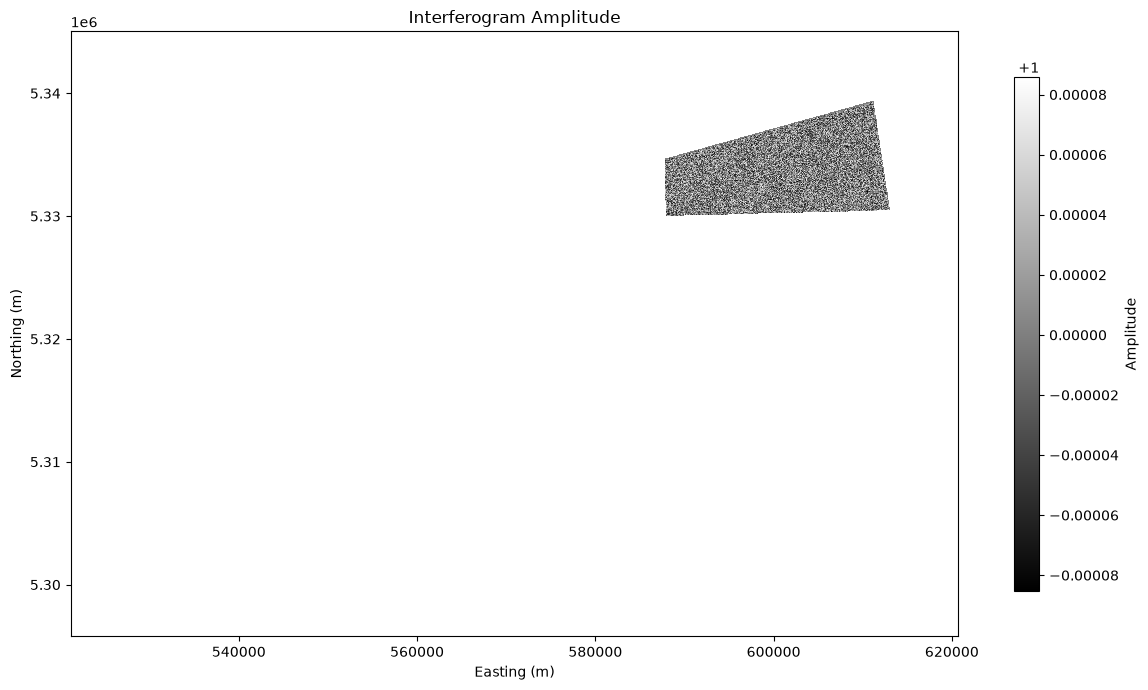

In [16]:
plot_interferogram_geographic(int_file)

## Plot all interferograms for phase 0 and amplitude 1

In [33]:
int_dir = Path(
    "/home/lukas/projects/ADUCAT/data/sweets_fork_testenv/"
    "dolphin/interferograms"
)

int_files = sorted(int_dir.glob("*.int.tif"))

print(f"Found {len(int_files)} interferograms")

Found 1 interferograms


In [34]:
int_files

[PosixPath('/home/lukas/projects/ADUCAT/data/sweets_fork_testenv/dolphin/interferograms/20250109_20250121.int.tif')]

20250109_20250121.int.tif: 0 matching pixels


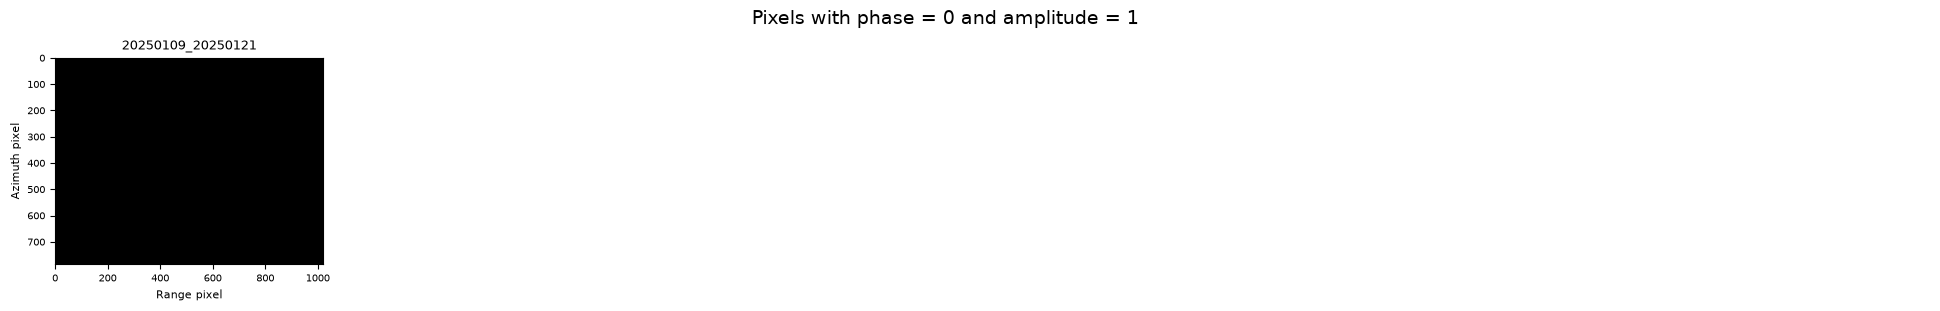

In [35]:
import math

# int_files contains your list of interferogram Path objects
ncols = 5
nrows = math.ceil(len(int_files) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4 * ncols, 3 * nrows),
    squeeze=False
)

tol = 0

for i, int_file in enumerate(int_files):
    row, col = divmod(i, ncols)
    ax = axes[row, col]

    # Read complex interferogram
    with rasterio.open(int_file) as src:
        z = src.read(1)

    phase = np.angle(z)
    amplitude = np.abs(z)

    # Select pixels with phase = 0 and amplitude = 1
    matches = (
        np.isfinite(z.real)
        & np.isfinite(z.imag)
        & np.isclose(phase, 0, atol=tol)
        & np.isclose(amplitude, 1, atol=tol)
    )

    print(f"{int_file.name}: {np.count_nonzero(matches):,} matching pixels")

    # Plot matching pixels
    ax.imshow(
        matches,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_title(int_file.name.replace(".int.tif", ""), fontsize=9)
    ax.set_xlabel("Range pixel", fontsize=8)
    ax.set_ylabel("Azimuth pixel", fontsize=8)
    ax.tick_params(labelsize=7)

# Hide unused subplots in the final row
for i in range(len(int_files), nrows * ncols):
    row, col = divmod(i, ncols)
    axes[row, col].axis("off")

fig.suptitle("Pixels with phase = 0 and amplitude = 1", fontsize=14)
plt.tight_layout()
plt.show()

## Plot linked phase slc files

In [ ]:
burst = "t073_154935_iw1"


# Path to the first interferogram
slc_linked_phase_file = Path(
    f"/home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/{burst}/linked_phase/20220101.slc.tif"
)

File: /home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/t073_154935_iw1/linked_phase/20220101.slc.tif


In [18]:
print(f"File exists: {slc_linked_phase_file.exists()}")
print(f"File: {slc_linked_phase_file}")

with rasterio.open(slc_linked_phase_file) as src:
    print(f"\nDimensions: {src.width} × {src.height}")
    print(f"Bands: {src.count}")
    print(f"Data type: {src.dtypes}")
    print(f"CRS: {src.crs}")
    print(f"Transform: {src.transform}")
    print(f"NoData value: {src.nodata}")

    z = src.read(1)

print(f"\nArray shape: {z.shape}")
print(f"Array dtype: {z.dtype}")
print(f"Finite pixels: {np.count_nonzero(np.isfinite(z)):,} / {z.size:,}")

File exists: True
File: /home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/t073_154935_iw1/linked_phase/20220101.slc.tif

Dimensions: 3319 × 1642
Bands: 1
Data type: ('complex64',)
CRS: EPSG:32633
Transform: | 30.00, 0.00, 521130.00|
| 0.00,-30.00, 5345040.00|
| 0.00, 0.00, 1.00|
NoData value: 0.0

Array shape: (1642, 3319)
Array dtype: complex64
Finite pixels: 5,449,798 / 5,449,798


In [19]:
# Basic statistics
zero_pixels = (z == 0)
phase = np.angle(z)
amplitude = np.abs(z)

phase0_amp1 = (
    np.isclose(phase, 0, atol=0, rtol=0)
    & np.isclose(amplitude, 1, atol=0, rtol=0)
)

print(f"Total pixels: {z.size:,}")
print(f"Exact zero pixels: {zero_pixels.sum():,} ({100 * zero_pixels.mean():.4f}%)")
print(f"Phase = 0 and amplitude = 1: {phase0_amp1.sum():,} "
      f"({100 * phase0_amp1.mean():.4f}%)")
print(f"Amplitude min/max: {amplitude.min():.6g} / {amplitude.max():.6g}")
print(f"Amplitude percentiles: {np.nanpercentile(amplitude, [0, 1, 25, 50, 75, 99, 100])}")

Total pixels: 5,449,798
Exact zero pixels: 5,263,693 (96.5851%)
Phase = 0 and amplitude = 1: 5 (0.0001%)
Amplitude min/max: 0 / 1
Amplitude percentiles: [0. 0. 0. 0. 0. 1. 1.]


Total pixels: 5,449,798
Nonzero pixels: 186,105 (3.41%)
Zero pixels: 5,263,693 (96.59%)

Amplitude percentiles within nonzero pixels:
[1. 1. 1. 1. 1. 1. 1.]

Phase percentiles within nonzero pixels (radians):
[-2.45869160e-07 -1.42054632e-07 -2.56841304e-08  9.04947228e-11
  2.64299160e-08  1.32044079e-07  2.62225512e-07]
Unique complex values (sample of up to 100,000 pixels): 59329


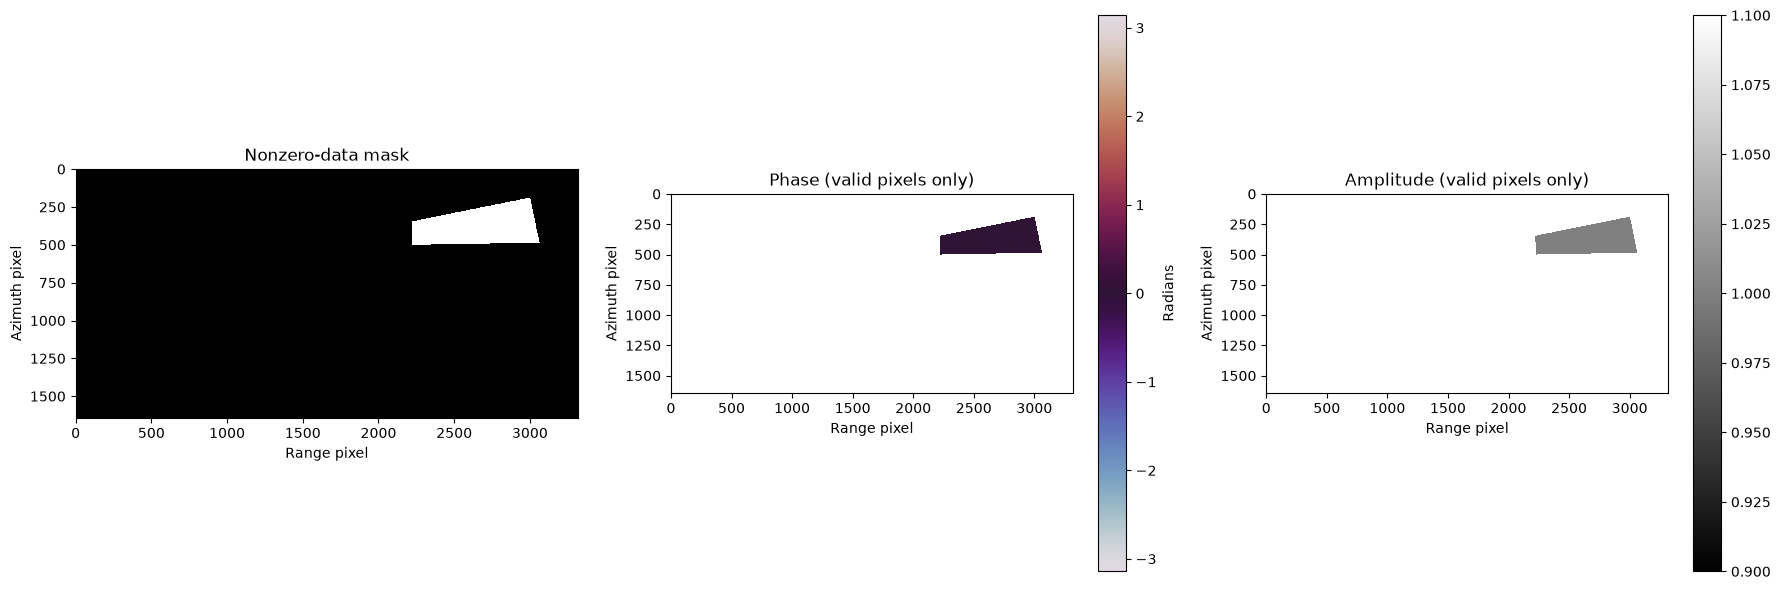

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio

with rasterio.open(slc_linked_phase_file) as src:
    z = src.read(1)
    nodata = src.nodata

amplitude = np.abs(z)
phase = np.angle(z)

# The file declares complex zero as NoData.
valid = np.isfinite(z.real) & np.isfinite(z.imag) & (z != 0)

print(f"Total pixels: {z.size:,}")
print(f"Nonzero pixels: {valid.sum():,} ({100 * valid.mean():.2f}%)")
print(f"Zero pixels: {(z == 0).sum():,} ({100 * np.mean(z == 0):.2f}%)")

if valid.any():
    print("\nAmplitude percentiles within nonzero pixels:")
    print(np.percentile(amplitude[valid], [0, 1, 25, 50, 75, 99, 100]))

    print("\nPhase percentiles within nonzero pixels (radians):")
    print(np.percentile(phase[valid], [0, 1, 25, 50, 75, 99, 100]))
    print(f"Unique complex values (sample of up to 100,000 pixels): "
          f"{np.unique(z[valid].ravel()[::max(1, valid.sum() // 100_000)]).size}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(valid, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title("Nonzero-data mask")

phase_plot = np.where(valid, phase, np.nan)
im1 = axes[1].imshow(
    phase_plot, cmap="twilight", vmin=-np.pi, vmax=np.pi,
    interpolation="nearest"
)
axes[1].set_title("Phase (valid pixels only)")
plt.colorbar(im1, ax=axes[1], label="Radians")

amp_plot = np.where(valid, amplitude, np.nan)
im2 = axes[2].imshow(amp_plot, cmap="gray", interpolation="nearest")
axes[2].set_title("Amplitude (valid pixels only)")
plt.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xlabel("Range pixel")
    ax.set_ylabel("Azimuth pixel")

plt.tight_layout()
plt.show()

In [25]:
# Use the valid mask from the previous code
phase_valid = phase[valid]

print(f"Number of valid pixels: {phase_valid.size:,}")
print(f"Minimum phase: {phase_valid.min():.12e} rad")
print(f"Maximum phase: {phase_valid.max():.12e} rad")
print(f"Mean phase:     {phase_valid.mean():.12e} rad")
print(f"Std. deviation: {phase_valid.std():.12e} rad")

print("\nPhase percentiles (radians):")
for p, value in zip(
    [0, 1, 5, 25, 50, 75, 95, 99, 100],
    np.percentile(phase_valid, [0, 1, 5, 25, 50, 75, 95, 99, 100])
):
    print(f"{p:3d}%: {value:.12e}")

Number of valid pixels: 186,105
Minimum phase: -2.458691596985e-07 rad
Maximum phase: 2.622255124152e-07 rad
Mean phase:     -7.463468176816e-10 rad
Std. deviation: 5.290543114711e-08 rad

Phase percentiles (radians):
  0%: -2.458691596985e-07
  1%: -1.420546323061e-07
  5%: -9.099312592298e-08
 25%: -2.568413037807e-08
 50%: 9.049472282641e-11
 75%: 2.642991603352e-08
 95%: 8.699134923518e-08
 99%: 1.320440787822e-07
100%: 2.622255124152e-07


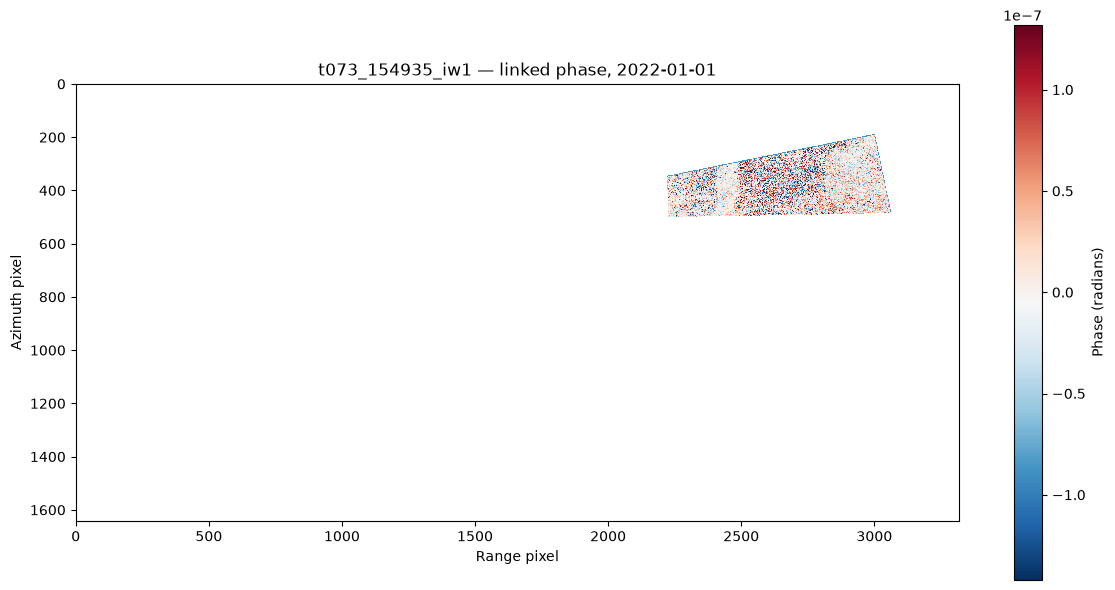

Color scale: -1.421e-07 to 1.320e-07 rad


In [26]:
vmin, vmax = np.percentile(phase_valid, [1, 99])

phase_plot = np.where(valid, phase, np.nan)

plt.figure(figsize=(12, 6))
im = plt.imshow(
    phase_plot,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

plt.title(f"{burst} — linked phase, 2022-01-01")
plt.xlabel("Range pixel")
plt.ylabel("Azimuth pixel")
plt.colorbar(im, label="Phase (radians)")
plt.tight_layout()
plt.show()

print(f"Color scale: {vmin:.3e} to {vmax:.3e} rad")